# 04 · Clustering

Can k-means recover the three sentiment groups from the supplied BERT embeddings? Start with raw embeddings at $k=3$, then vary the number of clusters and compare raw embeddings with row-wise L2 normalization. The EDA found that embedding lengths vary and that Neutral overlaps Negative and Positive.

On images, compare whether clusters align with object classes or with the two sparsity groups identified in the EDA.

**Model.** Use the project's NumPy `KMeans` with Euclidean distances, k-means++ initialization, and 10 starts per setting. Keep the start with the lowest training inertia.

**Validation.** Use the fixed 80/20 splits. Fit centroids on training vectors and assign validation vectors to their nearest centroid. Sentiment labels, object classes, and sparsity groups are used only to evaluate those assignments.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import adjusted_rand_score, silhouette_score

from comp472_project.clustering import KMeans
from comp472_project.config import FIGURES_DIR, RESULTS_DIR, SEED, SENTIMENT_LABELS
from comp472_project.data import load_split
from comp472_project.preprocessing import L2Normalizer, SqrtTransform

data = load_split("sentiment")
K_VALUES = (2, 3, 5, 8)
KMEANS_SETTINGS = {"n_init": 10, "max_iter": 300, "tol": 1e-4, "seed": SEED}
SENTIMENT_NAMES = list(SENTIMENT_LABELS.values())
sample_idx = np.random.default_rng(SEED).choice(len(data.X_val), size=1200, replace=False)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)


INK, INK2, AXIS, GRID, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "clustering_blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#184f95"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def fit_kmeans(X_train, X_val, k):
    model = KMeans(n_clusters=k, **KMEANS_SETTINGS)
    start = perf_counter()
    model.fit(X_train)
    fit_time = perf_counter() - start
    val_clusters = model.predict(X_val)
    return model, val_clusters, fit_time

## 1. Sentiment baseline with three clusters

Fit on the 9,600 sentiment training vectors and evaluate on the 2,400 validation vectors.

**Adjusted Rand index (ARI)** compares the validation clusters with true sentiments regardless of cluster numbering. A score near 0 means chance-level agreement, and 1 means identical partitions.

**Silhouette** measures how close validation examples are to their own cluster relative to the nearest other cluster. Compute it using Euclidean distances on the same seeded sample of 1,200 validation rows for every setting. **Training inertia** sums squared distances to the assigned centroids. Its magnitude depends on the feature scale, so compare it across $k$ within each preprocessing setting.

In [2]:
def run_kmeans(X_train, X_val, k, preprocessing):
    model, val_clusters, fit_time = fit_kmeans(X_train, X_val, k)
    sample_clusters = val_clusters[sample_idx]
    silhouette = silhouette_score(X_val[sample_idx], sample_clusters, metric="euclidean")

    # Keep every cluster and every sentiment in the table, including any empty rows.
    counts = (
        pd.crosstab(val_clusters, data.y_val)
        .reindex(index=range(k), columns=list(SENTIMENT_LABELS), fill_value=0)
        .rename(columns=SENTIMENT_LABELS)
        .rename_axis(index="cluster", columns="sentiment")
    )
    # For a label, find the cluster with the best balance of label coverage and purity.
    cluster_sizes = counts.sum(axis=1).to_numpy()[:, None]
    class_sizes = counts.sum(axis=0).to_numpy()
    cluster_f1 = 2 * counts / (cluster_sizes + class_sizes)
    row = {
        "task": data.task,
        "preprocessing": preprocessing,
        "k": k,
        **KMEANS_SETTINGS,
        "train_inertia": model.inertia_,
        "val_ari": adjusted_rand_score(data.y_val, val_clusters),
        "val_silhouette": silhouette,
        "silhouette_n": len(sample_idx),
        "val_clusters": np.unique(val_clusters).size,
        "n_iter": model.n_iter_,
        "fit_time_s": fit_time,
        **{f"best_cluster_f1_{label.lower()}": cluster_f1[label].max() for label in SENTIMENT_NAMES},
    }
    return row, counts


baseline, baseline_counts = run_kmeans(data.X_train, data.X_val, 3, "raw")
display(pd.DataFrame([baseline])[["k", "val_ari", "val_silhouette", "train_inertia", "n_iter"]])
baseline_counts.assign(Total=baseline_counts.sum(axis=1))

,k,val_ari,val_silhouette,train_inertia,n_iter
0,3,0.016,0.028,252153.082,26


sentiment,Negative,Neutral,Positive,Total
cluster,,,,
0,246,284,326,856
1,250,198,301,749
2,304,318,173,795


Each heatmap row shows the sentiment mix inside one cluster and sums to 100%. Cells also show counts, and the row labels give cluster sizes. The validation set is balanced, so one third is the expected share of each sentiment in a cluster with the same mix as the full set.

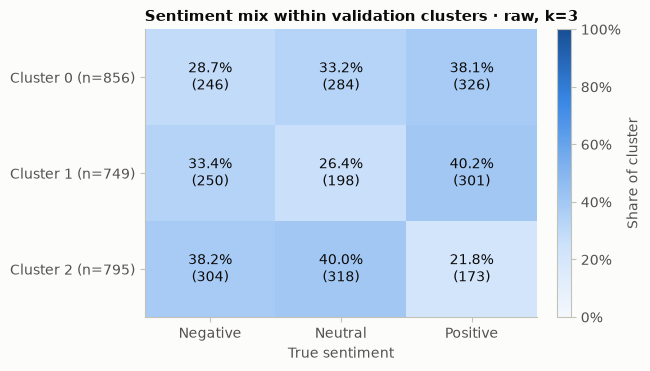

In [3]:
cluster_sizes = baseline_counts.sum(axis=1)
shares = baseline_counts.div(cluster_sizes.replace(0, np.nan), axis=0)
fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
colors = ax.imshow(shares, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(SENTIMENT_NAMES)), SENTIMENT_NAMES)
ax.set_yticks(
    range(len(cluster_sizes)),
    [f"Cluster {cluster} (n={size:,})" for cluster, size in cluster_sizes.items()],
)
ax.set(title="Sentiment mix within validation clusters · raw, k=3", xlabel="True sentiment")
ax.grid(False)
for cluster in baseline_counts.index:
    for column, sentiment in enumerate(SENTIMENT_NAMES):
        share = shares.loc[cluster, sentiment]
        annotation = f"{share:.1%}\n({baseline_counts.loc[cluster, sentiment]:,})" if cluster_sizes[cluster] else "—"
        ax.text(column, cluster, annotation, ha="center", va="center",
                color="white" if share >= 0.65 else INK)
colorbar = fig.colorbar(colors, ax=ax, format=PercentFormatter(xmax=1))
colorbar.set_label("Share of cluster")
fig.savefig(FIGURES_DIR / "clustering_sentiment_k3.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Effect of cluster count and normalization

Compare raw and L2-normalized embeddings at $k=2,3,5,8$. L2 normalization scales each vector to unit length. The raw $k=3$ result comes from the baseline above.

For each sentiment, **best cluster F1** is the highest F1 across clusters when treating membership in one cluster as a match for that sentiment. It balances the fraction of the sentiment captured by the cluster and the fraction of that cluster belonging to the sentiment. Different sentiments can pick the same cluster. Use the scores to see whether Neutral has a weaker association with any single cluster at the same $k$.

In [4]:
normalizer = L2Normalizer()
features = {
    "raw": (data.X_train, data.X_val),
    "l2": (normalizer.fit_transform(data.X_train), normalizer.transform(data.X_val)),
}
rows = []
for preprocessing, (X_train, X_val) in features.items():
    for k in K_VALUES:
        if (preprocessing, k) == ("raw", 3):
            row = baseline
        else:
            row, _ = run_kmeans(X_train, X_val, k, preprocessing)
        rows.append(row)
        print(f"{preprocessing:3s}  k={k}  ARI={row['val_ari']:.3f}  "
              f"silhouette={row['val_silhouette']:.3f}  ({row['fit_time_s']:.1f}s fit)")

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "clustering_sentiment.csv", index=False)
results.drop(columns=["task", *KMEANS_SETTINGS, "silhouette_n"])

raw  k=2  ARI=0.010  silhouette=0.039  (8.3s fit)
raw  k=3  ARI=0.016  silhouette=0.028  (15.5s fit)


raw  k=5  ARI=0.018  silhouette=0.024  (17.1s fit)


raw  k=8  ARI=0.020  silhouette=0.023  (20.4s fit)


l2   k=2  ARI=0.008  silhouette=0.040  (7.6s fit)


l2   k=3  ARI=0.013  silhouette=0.028  (15.0s fit)


l2   k=5  ARI=0.018  silhouette=0.025  (19.5s fit)


l2   k=8  ARI=0.026  silhouette=0.022  (20.3s fit)


,preprocessing,k,train_inertia,val_ari,val_silhouette,val_clusters,n_iter,fit_time_s,best_cluster_f1_negative,best_cluster_f1_neutral,best_cluster_f1_positive
0,raw,2,258506.317,0.010,0.039,2,21,8.346,0.461,0.424,0.458
1,raw,3,252153.082,0.016,0.028,3,26,15.530,0.381,0.399,0.394
2,raw,5,243106.874,0.018,0.024,5,51,17.123,0.365,0.287,0.329
3,raw,8,234768.028,0.020,0.023,8,45,20.376,0.352,0.311,0.324
4,l2,2,3186.352,0.008,0.040,2,24,7.599,0.456,0.420,0.454
5,l2,3,3108.572,0.013,0.028,3,41,14.996,0.372,0.385,0.390
6,l2,5,2999.236,0.018,0.025,5,48,19.506,0.358,0.276,0.340
7,l2,8,2902.801,0.026,0.022,8,67,20.258,0.353,0.254,0.278


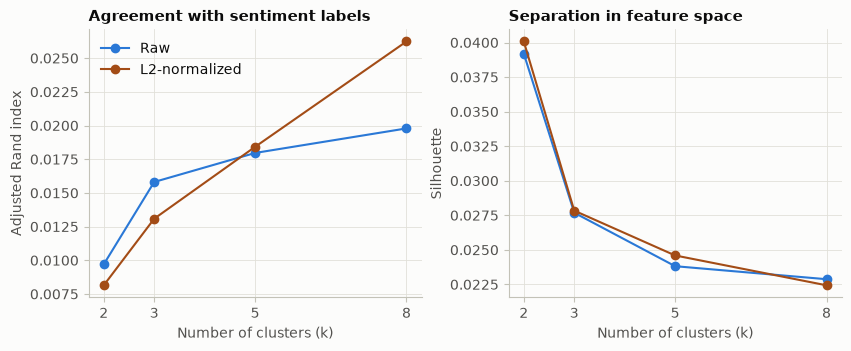

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4), layout="constrained")
for preprocessing, group in results.groupby("preprocessing", sort=False):
    label = "Raw" if preprocessing == "raw" else "L2-normalized"
    color = "#2a78d6" if preprocessing == "raw" else "#a34c16"
    for ax, metric in zip(axes, ("val_ari", "val_silhouette")):
        ax.plot(group["k"], group[metric], marker="o", color=color, label=label)

axes[0].set(title="Agreement with sentiment labels", ylabel="Adjusted Rand index")
axes[1].set(title="Separation in feature space", ylabel="Silhouette")
axes[0].legend()
for ax in axes:
    ax.set(xlabel="Number of clusters (k)", xticks=K_VALUES)
fig.savefig(FIGURES_DIR / "clustering_sentiment_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. What the clusters tell us

**The baseline mixes the three sentiments.** Raw embeddings at $k=3$ give an ARI of 0.016 and a silhouette of 0.028. The largest cluster has 856 texts and is 38.1% Positive, 33.2% Neutral, and 28.7% Negative. Across all three clusters, the biggest share for any sentiment is 40.2%.

**More clusters increase label agreement slightly.** ARI rises with $k$ in both representations, while silhouette drops from about 0.040 at $k=2$ to about 0.022 at $k=8$. L2 normalization gives the highest ARI at $k=8$ (0.026), and agreement remains close to chance across the sweep.

**Neutral is often the least concentrated in a single cluster.** It has the lowest best-cluster F1 in six of the eight settings. The two $k=3$ settings are the exceptions. In the raw baseline, the cluster with the most Neutral texts contains 318 of the 800 Neutral examples and also contains 304 Negative texts.

## 4. Image clusters and feature sparsity

Do image clusters align more strongly with the sparse and dense groups from [the EDA](01_eda.ipynb) or with the 50 object classes? Run k-means at $k=2$ and $k=50$ on both raw and square-rooted image histograms. The square root compresses differences between large and small feature values and also changes the length of each vector.

Fit on the 16,000 training images and score assignments for the 4,000 validation images. As in the EDA, an image is **dense** when more than 80 of its 500 raw feature bins are positive, and **sparse** otherwise. Use that same grouping for both representations.

Compute ARI against each reference partition. At $k=50$, several clusters can subdivide the same sparsity group, which lowers agreement with the two-group partition even when individual clusters mostly contain one group. The **majority sparsity share** gives the fraction of validation images in their cluster’s majority sparsity group. Compare it with the share of the larger sparsity group over all validation images.

In [6]:
image_data = load_split("image")
image_dense = (image_data.X_val > 0).sum(axis=1) > 80
image_k_values = (2, image_data.n_classes)
sqrt = SqrtTransform()
image_features = {
    "raw": (image_data.X_train, image_data.X_val),
    "sqrt": (sqrt.fit_transform(image_data.X_train), sqrt.transform(image_data.X_val)),
}
image_rows = []
image_sparsity_counts = {}
for preprocessing, (X_train, X_val) in image_features.items():
    for k in image_k_values:
        model, val_clusters, fit_time = fit_kmeans(X_train, X_val, k)
        counts = (
            pd.crosstab(val_clusters, image_dense)
            .reindex(index=range(k), columns=[False, True], fill_value=0)
            .set_axis(["Sparse", "Dense"], axis=1)
            .rename_axis(index="cluster")
        )
        image_sparsity_counts[preprocessing, k] = counts
        ari_sparsity = adjusted_rand_score(image_dense, val_clusters)
        ari_classes = adjusted_rand_score(image_data.y_val, val_clusters)
        image_rows.append({
            "task": image_data.task,
            "preprocessing": preprocessing,
            "k": k,
            **KMEANS_SETTINGS,
            "val_ari_sparsity": ari_sparsity,
            "val_ari_object_class": ari_classes,
            "val_majority_sparsity_share": counts.max(axis=1).sum() / len(val_clusters),
            "val_clusters": np.unique(val_clusters).size,
            "n_iter": model.n_iter_,
            "fit_time_s": fit_time,
        })
        print(f"{preprocessing:4s}  k={k:2d}  sparsity ARI={ari_sparsity:.3f}  "
              f"object class ARI={ari_classes:.3f}  ({fit_time:.1f}s fit)")

image_results = pd.DataFrame(image_rows)
image_results.to_csv(RESULTS_DIR / "clustering_image.csv", index=False)
image_results.drop(columns=["task", *KMEANS_SETTINGS])

raw   k= 2  sparsity ARI=0.773  object class ARI=0.000  (4.7s fit)


raw   k=50  sparsity ARI=0.035  object class ARI=0.026  (43.3s fit)


sqrt  k= 2  sparsity ARI=0.824  object class ARI=0.000  (5.3s fit)


sqrt  k=50  sparsity ARI=0.041  object class ARI=0.027  (38.9s fit)


,preprocessing,k,val_ari_sparsity,val_ari_object_class,val_majority_sparsity_share,val_clusters,n_iter,fit_time_s
0,raw,2,0.773,4.319e-04,0.940,2,9,4.741
1,raw,50,0.035,2.645e-02,0.938,50,50,43.300
2,sqrt,2,0.824,2.165e-04,0.954,2,8,5.281
3,sqrt,50,0.041,2.663e-02,0.963,50,64,38.938


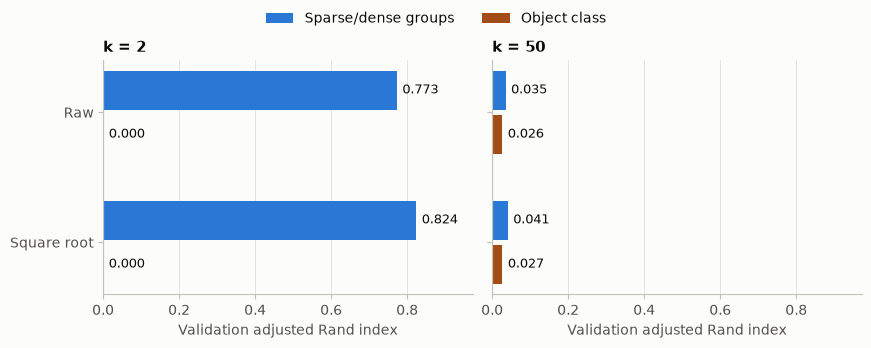

In [7]:
image_plot = image_results.set_index(["k", "preprocessing"])
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4), sharex=True, sharey=True, layout="constrained")
references = [
    ("val_ari_sparsity", "Sparse/dense groups", "#2a78d6"),
    ("val_ari_object_class", "Object class", "#a34c16"),
]
y = np.arange(len(image_features))
for ax, k in zip(axes, image_k_values):
    rows_for_k = image_plot.loc[k]
    for offset, (column, label, color) in zip((-0.17, 0.17), references):
        bars = ax.barh(y + offset, rows_for_k[column], height=0.3, color=color, label=label)
        ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
    ax.axvline(0, linewidth=0.8, color=AXIS)
    ax.set(title=f"k = {k}", xlabel="Validation adjusted Rand index")
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.18)
axes[0].set_yticks(y, ["Raw", "Square root"])
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=2)
fig.savefig(FIGURES_DIR / "clustering_image_alignment.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
image_k2_counts = pd.concat(
    {preprocessing: image_sparsity_counts[preprocessing, 2] for preprocessing in image_features},
    names=["preprocessing"],
)
print(f"Dense share across all validation images: {image_dense.mean():.1%}")
image_k2_counts.assign(
    Total=image_k2_counts.sum(axis=1),
    **{"Dense share": image_k2_counts["Dense"] / image_k2_counts.sum(axis=1)},
).style.format({"Dense share": "{:.1%}"})

Dense share across all validation images: 38.5%


### What the image clusters capture

**Two clusters largely recover the sparse/dense split.** Sparsity ARI is 0.773 on raw features and 0.824 after the square root. With square-rooted features, one cluster is 94.4% sparse and the other is 97.2% dense. Object-class ARI is near zero for both two-cluster runs.

**Fifty clusters still group images with similar sparsity.** Sparsity ARI is only 0.035 (raw) or 0.041 (square root) when comparing 50 clusters with two groups. Yet 93.8% or 96.3% of validation images, respectively, belong to their cluster’s majority sparsity group. Putting every image into one cluster would give 61.5%. Agreement with the 50 object labels is weak even at $k=50$ (ARI 0.026–0.027).